# 🍷 Tech Challenge Fase 2 — Classificação da Qualidade de Vinhos
## Notebook 03 · Desenvolvimento e Avaliação dos Modelos

Etapas 4 e 5 do desafio: treinar pelo menos dois modelos de classificação, avaliá-los com métricas adequadas e compará-los.

## 4.1 Estratégia de modelagem

**Modelos avaliados**

| Modelo | Por que foi escolhido |
|---|---|
| **Baseline** (sempre prevê "baixa/média") | Referência mínima: qualquer modelo útil precisa superá-lo |
| **Regressão Logística** | Modelo linear, simples e **interpretável** (coeficientes); referência clássica |
| **Random Forest** | Conjunto de árvores; captura relações não lineares e interações, robusto a outliers e multicolinearidade |
| **Gradient Boosting** (`HistGradientBoosting`) | Árvores construídas em sequência, cada uma corrigindo os erros da anterior; costuma ser o estado da arte em dados tabulares |

**Como lidamos com o desbalanceamento (13,5% de alta qualidade)**
- **Pesos de classe** (`class_weight="balanced"`): erros na classe rara custam mais no treinamento, sem criar dados sintéticos.
- **Ajuste do limiar de decisão**: em vez do 0,5 padrão, escolhemos o limiar que maximiza o F1 — usando apenas o treino.

**Métricas** (sempre para a classe "alta qualidade")
- **PR-AUC** (*average precision*): métrica principal — resume o equilíbrio precisão × recall e é a mais informativa para classes raras.
- **ROC-AUC**: capacidade geral de ordenar vinhos bons acima dos comuns.
- **F1, Precisão e Recall** no limiar escolhido.
  - *Precisão*: dos vinhos que o modelo aponta como excelentes, quantos realmente são.
  - *Recall*: dos vinhos excelentes, quantos o modelo encontra.
- A **acurácia** é exibida apenas como referência — o baseline já atinge ~86% sem prever nada útil.

**Protocolo sem vazamento**
1. Teste (20%) fica separado até o final.
2. Comparações e escolha de hiperparâmetros: **validação cruzada estratificada** (5 folds × 3 repetições) só no treino.
3. Pré-processamento dentro do `Pipeline` — reajustado a cada fold.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve

from src.config import RESULTS_DIR, TARGET_COL
from src.data_loader import load_dataset
from src.preprocessing import prepare_data
from src.modeling import (MODEL_NAMES_PT, get_estimators, make_pipeline, cross_validate_model, tune_model,
                          find_best_threshold, evaluate, cv_splitter)
from src.visualization import set_style, save_fig, COLOR_LOW, COLOR_HIGH, COLOR_ACCENT, INK_2

set_style()
pd.set_option("display.float_format", "{:.3f}".format)
MODELS_DIR = RESULTS_DIR / "models"; MODELS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_COLORS = {"logistic": COLOR_LOW, "random_forest": COLOR_ACCENT, "gradient_boosting": "#6250d6", "baseline": "#a9a8a2"}

df = load_dataset()
sets = {}
for fe in [False, True]:
    X_train, X_test, y_train, y_test, feats, logs = prepare_data(df, use_engineered=fe)
    sets[fe] = dict(X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test, features=feats, log_features=logs)
    print(f"{'Com' if fe else 'Sem'} feature engineering: {len(feats)} variáveis | treino {X_train.shape[0]} | teste {X_test.shape[0]}")

# Mesmo split nos dois cenários (mesmos vinhos em treino e teste)
assert sets[False]["X_test"].index.equals(sets[True]["X_test"].index)

Sem feature engineering: 11 variáveis | treino 1087 | teste 272
Com feature engineering: 15 variáveis | treino 1087 | teste 272


## 4.2 Comparação inicial — com e sem as features criadas

Antes de ajustar hiperparâmetros, comparamos os modelos com configuração padrão nos dois conjuntos de variáveis: as **11 originais** e as **11 + 4 criadas** no notebook 02. Assim verificamos se a feature engineering realmente agrega.

In [2]:
rows = []
for fe, s in sets.items():
    for name, est in get_estimators().items():
        res = cross_validate_model(make_pipeline(est, s["features"], s["log_features"]), s["X_train"], s["y_train"])
        rows.append({"modelo": MODEL_NAMES_PT[name], "chave": name,
                     "features": "11 originais + 4 criadas" if fe else "11 originais", **res})
cv_initial = pd.DataFrame(rows)
cv_initial.to_csv(RESULTS_DIR / "cv_comparacao_inicial.csv", index=False)

view = cv_initial.pivot_table(index="modelo", columns="features", values=["pr_auc", "roc_auc", "f1"], sort=False)
view

pr_auc                           \
features                        11 originais 11 originais + 4 criadas   
modelo                                                                  
Baseline (sempre 'baixa/média')        0.135                    0.135   
Regressão Logística                    0.530                    0.527   
Random Forest                          0.560                    0.565   
Gradient Boosting                      0.535                    0.517   

                                     roc_auc                           \
features                        11 originais 11 originais + 4 criadas   
modelo                                                                  
Baseline (sempre 'baixa/média')        0.500                    0.500   
Regressão Logística                    0.876                    0.875   
Random Forest                          0.879                    0.875   
Gradient Boosting                      0.871                    0.862   

                                          f1                           
features                        11 originais 11 originais + 4 criadas  
modelo                                                                 
Baseline (sempre 'baixa/média')        0.000                    0.000  
Regressão Logística                    0.517                    0.517  
Random Forest                          0.402                    0.422  
Gradient Boosting                      0.497                    0.475

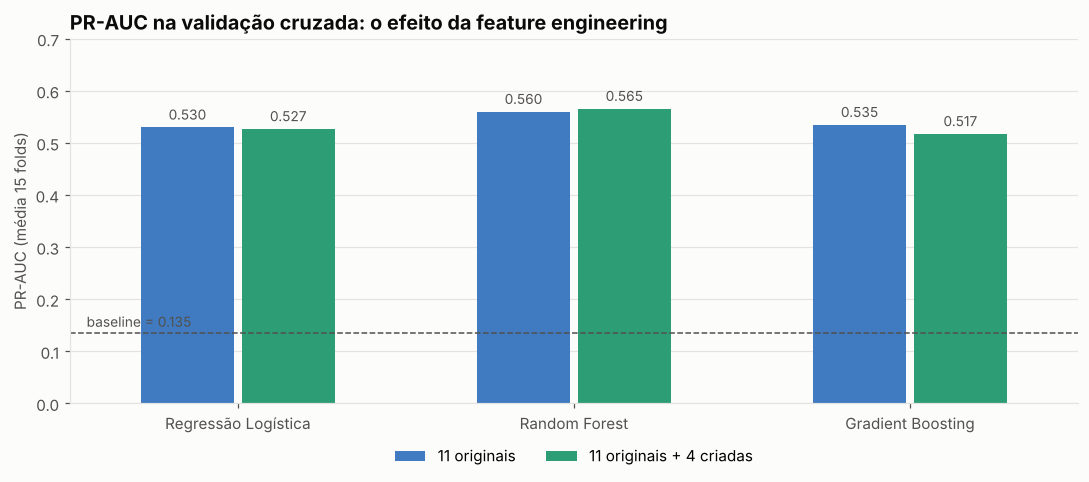

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
plot = cv_initial[cv_initial.chave != "baseline"]
order = [MODEL_NAMES_PT[k] for k in ["logistic", "random_forest", "gradient_boosting"]]
sns.barplot(data=plot, x="modelo", y="pr_auc", hue="features", order=order,
            palette=[COLOR_LOW, COLOR_ACCENT], ax=ax, width=0.6, gap=0.08)
for cont in ax.containers: ax.bar_label(cont, fmt="%.3f", padding=3, color=INK_2, fontsize=9)
base = cv_initial.loc[cv_initial.chave == "baseline", "pr_auc"].iloc[0]
ax.axhline(base, color=INK_2, ls="--", lw=1); ax.text(-0.45, base + 0.012, f"baseline = {base:.3f}", color=INK_2, ha="left", fontsize=9)
ax.set(title="PR-AUC na validação cruzada: o efeito da feature engineering", xlabel="", ylabel="PR-AUC (média 15 folds)", ylim=(0, 0.7))
ax.legend(title="", loc="upper center", ncols=2, bbox_to_anchor=(0.5, -0.08)); ax.grid(axis="x", visible=False)
plt.tight_layout(); save_fig(fig, "12_cv_feature_engineering"); plt.show()

In [4]:
mean_pr = cv_initial[cv_initial.chave != "baseline"].groupby("features")["pr_auc"].mean()
print("PR-AUC média dos 3 modelos:"); print(mean_pr.round(4).to_string())
USE_FE = bool(mean_pr["11 originais + 4 criadas"] > mean_pr["11 originais"] + 0.005)  # exige ganho mínimo
print(f"\n→ Conjunto escolhido: {'com' if USE_FE else 'sem'} feature engineering")
FS_LABEL = "11 originais + 4 criadas" if USE_FE else "11 originais"
S = sets[USE_FE]
X_train, X_test, y_train, y_test = S["X_train"], S["X_test"], S["y_train"], S["y_test"]
FEATS, LOGS = S["features"], S["log_features"]

PR-AUC média dos 3 modelos:
features
11 originais               0.541
11 originais + 4 criadas   0.536

→ Conjunto escolhido: sem feature engineering


**Resultado: a feature engineering não trouxe ganho consistente.**

| Modelo | PR-AUC 11 originais | PR-AUC com 4 criadas | Diferença |
|---|---|---|---|
| Regressão Logística | 0,530 | 0,527 | −0,003 |
| Random Forest | 0,560 | 0,565 | +0,005 |
| Gradient Boosting | 0,535 | 0,517 | −0,018 |

As diferenças são muito menores que a variação entre folds (desvio-padrão ≈ 0,07–0,09), ou seja, estão dentro do ruído. **Por que isso acontece?** As novas variáveis são combinações das originais: a Regressão Logística já pondera álcool e sulfatos juntos, e os modelos de árvore aprendem essas interações sozinhos. Elas ajudaram a **entender** o problema na EDA (Álcool × Sulfatos é a variável mais correlacionada com a qualidade), mas não acrescentam informação nova para o modelo.

**Decisão:** seguir com as **11 variáveis originais** — modelo mais simples, com o mesmo desempenho e mais fácil de explicar à equipe de produção (cada variável é uma medida que o laboratório já faz).

## 4.3 Ajuste de hiperparâmetros

`GridSearchCV` com validação cruzada estratificada (5 folds), **otimizando a PR-AUC**. As grades priorizam parâmetros que controlam *overfitting* — importante com apenas ~1.100 vinhos no treino:

- **Regressão Logística:** força da regularização (`C`) e tipo (L2, L1 ou mistura).
- **Random Forest:** profundidade máxima, mínimo de amostras por folha e nº de variáveis por divisão.
- **Gradient Boosting:** taxa de aprendizado, profundidade, nº de iterações, mínimo por folha e regularização L2.

In [5]:
tuned = {}
rows = []
for name in ["logistic", "random_forest", "gradient_boosting"]:
    grid = tune_model(name, FEATS, LOGS, X_train, y_train)
    tuned[name] = grid.best_estimator_
    rows.append({"modelo": MODEL_NAMES_PT[name], "PR-AUC na busca (CV 5 folds)": grid.best_score_,
                 "melhores hiperparâmetros": {k.replace("model__", ""): v for k, v in grid.best_params_.items() if k != "model__solver"}})
tuning = pd.DataFrame(rows)
tuning.to_csv(RESULTS_DIR / "tuning_hiperparametros.csv", index=False)
pd.set_option("display.max_colwidth", 200)
tuning

,modelo,PR-AUC na busca (CV 5 folds),melhores hiperparâmetros
0,Regressão Logística,0.523,"{'C': 0.03, 'l1_ratio': 0.0}"
1,Random Forest,0.550,"{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}"
2,Gradient Boosting,0.533,"{'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 200, 'min_samples_leaf': 10}"


In [6]:
# Avaliação completa (15 folds) dos modelos ajustados — ainda só no treino
rows = []
for name, pipe in tuned.items():
    rows.append({"modelo": MODEL_NAMES_PT[name], **cross_validate_model(pipe, X_train, y_train)})
cv_tuned = pd.DataFrame(rows).set_index("modelo")
default_pr = cv_initial[cv_initial.features == FS_LABEL].set_index("modelo")["pr_auc"]
cv_tuned.insert(0, "pr_auc_padrão", default_pr.reindex(cv_tuned.index))
cv_tuned.to_csv(RESULTS_DIR / "cv_modelos_ajustados.csv")
# Mesma validação (5 folds × 3 repetições) para comparar padrão × ajustado de forma justa
cv_tuned[["pr_auc_padrão", "pr_auc", "pr_auc_std", "roc_auc", "f1", "recall", "precision"]]

,pr_auc_padrão,pr_auc,pr_auc_std,roc_auc,f1,recall,precision
modelo,,,,,,,
Regressão Logística,0.530,0.534,0.082,0.878,0.524,0.832,0.384
Random Forest,0.560,0.557,0.072,0.876,0.432,0.322,0.662
Gradient Boosting,0.535,0.537,0.088,0.863,0.509,0.587,0.456


**Leitura:** comparando na **mesma validação** (5 folds × 3 repetições), o ajuste de hiperparâmetros mudou pouco a PR-AUC (Logística 0,530 → 0,534; Random Forest 0,560 → 0,557; Gradient Boosting 0,535 → 0,537). Com ~1.100 vinhos no treino e apenas 147 de alta qualidade, a configuração padrão já era adequada e as variações ficam dentro do ruído. O ajuste ainda é útil por escolher configurações **mais conservadoras** — regularização L2 mais forte na Logística (`C = 0,03`) e árvores rasas no Gradient Boosting (`max_depth = 3`) —, que tendem a generalizar melhor.

Os três modelos ficam muito próximos: **ROC-AUC ≈ 0,87–0,88**, ou seja, em ~87% das vezes o modelo dá nota maior a um vinho excelente do que a um vinho comum escolhido ao acaso. Já a PR-AUC (~0,53–0,56) é **4 vezes maior que a do baseline (0,135)**.

## 4.4 Ajuste do limiar de decisão

Por padrão, o modelo classifica como "alta qualidade" quando a probabilidade é ≥ 0,5. Com classes desbalanceadas e pesos de classe, esse corte raramente é o melhor. Escolhemos o limiar que **maximiza o F1** usando previsões *out-of-fold* do treino (cada vinho do treino é previsto por um modelo que não o viu). O teste continua intocado.

In [7]:
thresholds, oof, f1_oof = {}, {}, {}
for name, pipe in tuned.items():
    thr, f1_best, proba = find_best_threshold(pipe, X_train, y_train)
    thresholds[name], oof[name], f1_oof[name] = thr, proba, f1_best
pd.DataFrame({"limiar escolhido": thresholds, "F1 out-of-fold (treino)": f1_oof}).rename(index=MODEL_NAMES_PT)

,limiar escolhido,F1 out-of-fold (treino)
Regressão Logística,0.669,0.556
Random Forest,0.200,0.520
Gradient Boosting,0.559,0.519


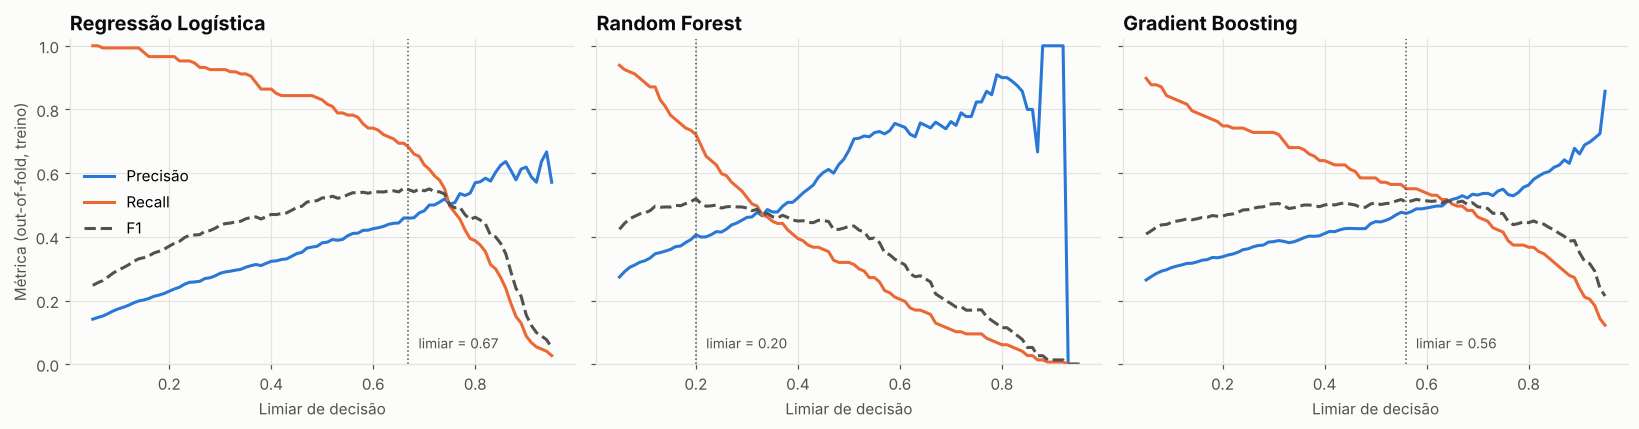

In [8]:
from sklearn.metrics import f1_score, precision_score, recall_score
grid_t = np.linspace(0.05, 0.95, 91)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, proba) in zip(axes, oof.items()):
    p = [precision_score(y_train, proba >= t, zero_division=0) for t in grid_t]
    r = [recall_score(y_train, proba >= t) for t in grid_t]
    f = [f1_score(y_train, proba >= t) for t in grid_t]
    ax.plot(grid_t, p, color=COLOR_LOW, lw=2, label="Precisão")
    ax.plot(grid_t, r, color=COLOR_HIGH, lw=2, label="Recall")
    ax.plot(grid_t, f, color=INK_2, lw=2, ls="--", label="F1")
    ax.axvline(thresholds[name], color=INK_2, lw=1, ls=":")
    ax.text(thresholds[name] + 0.02, 0.05, f"limiar = {thresholds[name]:.2f}", color=INK_2, fontsize=9)
    ax.set(title=MODEL_NAMES_PT[name], xlabel="Limiar de decisão", ylim=(0, 1.02))
axes[0].set_ylabel("Métrica (out-of-fold, treino)"); axes[0].legend(loc="center left")
plt.tight_layout(); save_fig(fig, "13_ajuste_limiar"); plt.show()

O gráfico mostra o *trade-off* clássico: **limiar baixo** → o modelo aponta muitos vinhos como excelentes (alto recall, baixa precisão); **limiar alto** → aponta poucos, mas acerta mais (alta precisão, baixo recall). O ponto marcado é o que equilibra os dois (máximo F1).

---
# 5. Avaliação final no conjunto de teste

Agora, e só agora, usamos os 272 vinhos do teste — que nenhum modelo viu em nenhuma etapa.

In [9]:
test_proba = {name: pipe.predict_proba(X_test)[:, 1] for name, pipe in tuned.items()}
base_proba = make_pipeline(get_estimators()["baseline"], FEATS, LOGS).fit(X_train, y_train).predict_proba(X_test)[:, 1]

rows = [{"modelo": MODEL_NAMES_PT["baseline"], **evaluate(y_test, base_proba, 0.5)}]
for name, proba in test_proba.items():
    rows.append({"modelo": MODEL_NAMES_PT[name], **evaluate(y_test, proba, thresholds[name])})
results = pd.DataFrame(rows).set_index("modelo")
results.to_csv(RESULTS_DIR / "metricas_teste.csv")
results

,ROC-AUC,PR-AUC,F1,Precisão,Recall,Acurácia balanceada,Acurácia,Limiar
modelo,,,,,,,,
Baseline (sempre 'baixa/média'),0.500,0.136,0.000,0.000,0.000,0.500,0.864,0.500
Regressão Logística,0.892,0.569,0.565,0.500,0.649,0.773,0.864,0.669
Random Forest,0.873,0.574,0.489,0.404,0.622,0.738,0.824,0.200
Gradient Boosting,0.896,0.592,0.564,0.537,0.595,0.757,0.875,0.559


In [10]:
# Referência: mesmos modelos com o limiar padrão de 0,5
pd.DataFrame({MODEL_NAMES_PT[n]: evaluate(y_test, p, 0.5) for n, p in test_proba.items()}).T[["F1", "Precisão", "Recall", "Acurácia"]]

,F1,Precisão,Recall,Acurácia
Regressão Logística,0.520,0.372,0.865,0.783
Random Forest,0.483,0.667,0.378,0.890
Gradient Boosting,0.578,0.522,0.649,0.871


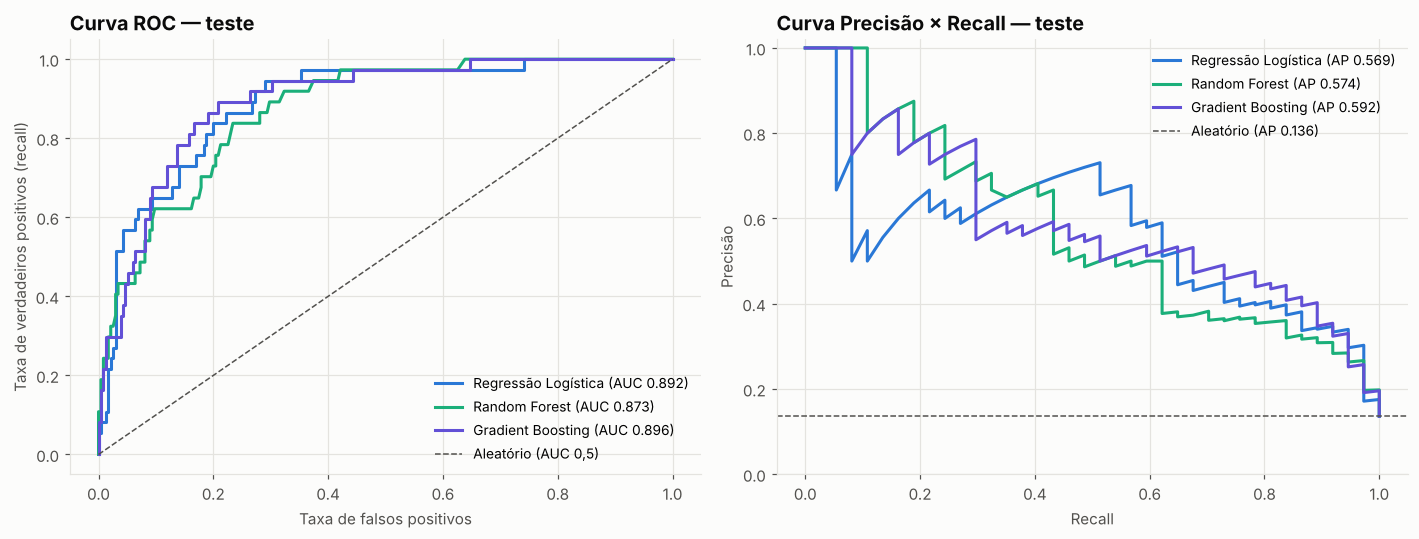

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, proba in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, lw=2, color=MODEL_COLORS[name], label=f"{MODEL_NAMES_PT[name]} (AUC {results.loc[MODEL_NAMES_PT[name], 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, lw=2, color=MODEL_COLORS[name], label=f"{MODEL_NAMES_PT[name]} (AP {results.loc[MODEL_NAMES_PT[name], 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color=INK_2, lw=1, label="Aleatório (AUC 0,5)")
axes[0].set(title="Curva ROC — teste", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (recall)")
axes[1].axhline(y_test.mean(), ls="--", color=INK_2, lw=1, label=f"Aleatório (AP {y_test.mean():.3f})")
axes[1].set(title="Curva Precisão × Recall — teste", xlabel="Recall", ylabel="Precisão", ylim=(0, 1.02))
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=9)
plt.tight_layout(); save_fig(fig, "14_curvas_roc_pr"); plt.show()

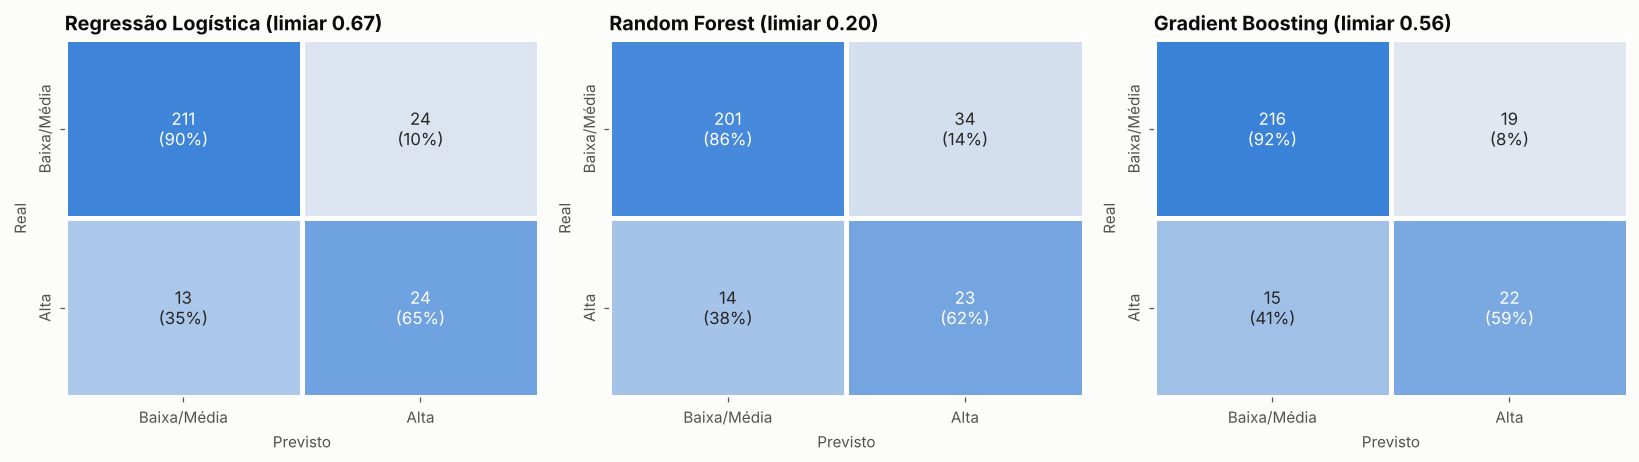

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
labels = ["Baixa/Média", "Alta"]
for ax, (name, proba) in zip(axes, test_proba.items()):
    cm = confusion_matrix(y_test, (proba >= thresholds[name]).astype(int))
    annot = np.array([[f"{v}\n({v / cm[i].sum():.0%})" for v in row] for i, row in enumerate(cm)])
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=annot, vmin=0, vmax=1, fmt="", cmap=sns.light_palette(COLOR_LOW, as_cmap=True), cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax, linewidths=2, linecolor="white", annot_kws={"size": 11})
    ax.set(title=f"{MODEL_NAMES_PT[name]} (limiar {thresholds[name]:.2f})", xlabel="Previsto", ylabel="Real"); ax.grid(False)
plt.tight_layout(); save_fig(fig, "15_matrizes_confusao"); plt.show()

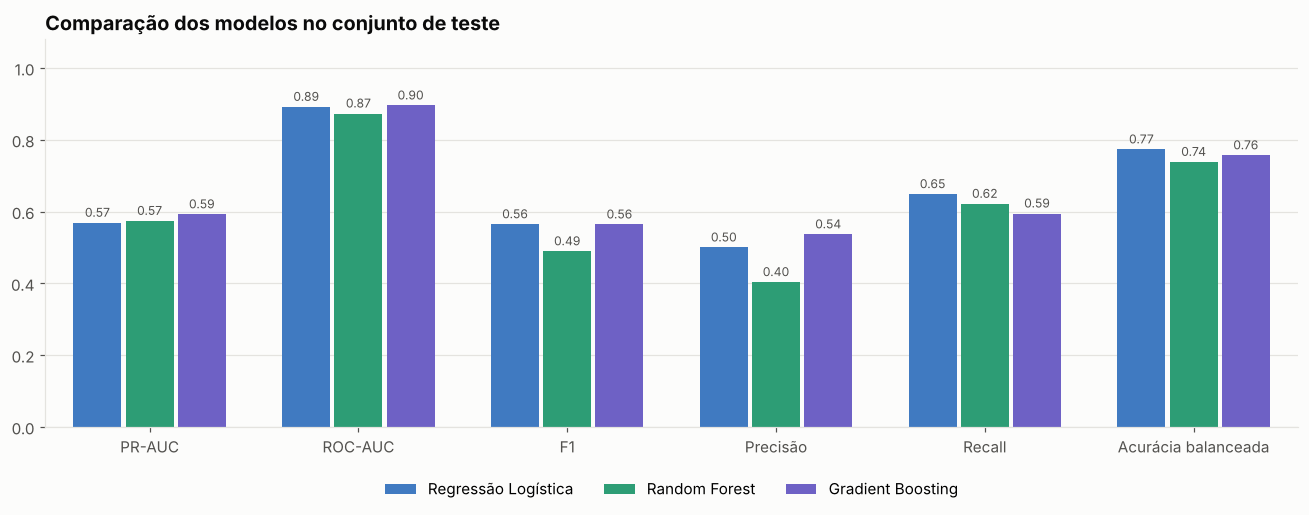

In [13]:
metrics_show = ["PR-AUC", "ROC-AUC", "F1", "Precisão", "Recall", "Acurácia balanceada"]
long = results.drop(index=MODEL_NAMES_PT["baseline"])[metrics_show].reset_index().melt(id_vars="modelo", var_name="métrica", value_name="valor")
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.barplot(data=long, x="métrica", y="valor", hue="modelo",
            palette=[MODEL_COLORS[k] for k in ["logistic", "random_forest", "gradient_boosting"]], ax=ax, width=0.75, gap=0.08)
for cont in ax.containers: ax.bar_label(cont, fmt="%.2f", padding=2, color=INK_2, fontsize=8)
ax.set(title="Comparação dos modelos no conjunto de teste", xlabel="", ylabel="", ylim=(0, 1.08))
ax.legend(title="", loc="upper center", ncols=3, bbox_to_anchor=(0.5, -0.1)); ax.grid(axis="x", visible=False)
plt.tight_layout(); save_fig(fig, "16_comparacao_modelos_teste"); plt.show()

## 5.1 Escolha do modelo final

A escolha usa **somente o treino** (validação cruzada) — o teste serve para confirmar, não para escolher. Regra:

1. **PR-AUC na validação cruzada** (métrica principal). Modelos cuja PR-AUC está a menos de **1 desvio-padrão** do melhor são considerados **estatisticamente empatados** — a diferença está dentro da variação natural entre folds.
2. Entre os empatados, vence o maior **F1 out-of-fold** no limiar ajustado — o desempenho na decisão real (aprovar ou não um vinho como "alta qualidade").

In [14]:
sel = cv_tuned[["pr_auc", "pr_auc_std"]].copy()
sel["F1 out-of-fold"] = pd.Series(f1_oof).rename(index=MODEL_NAMES_PT)
top = sel["pr_auc"].idxmax()
cutoff = sel.loc[top, "pr_auc"] - sel.loc[top, "pr_auc_std"]
sel["empatado com o melhor?"] = np.where(sel["pr_auc"] >= cutoff, "sim", "não")
display(sel.sort_values("pr_auc", ascending=False))
best_pt = sel[sel["empatado com o melhor?"] == "sim"]["F1 out-of-fold"].idxmax()
BEST = {v: k for k, v in MODEL_NAMES_PT.items()}[best_pt]
print(f"Faixa de empate: PR-AUC ≥ {cutoff:.3f}")
print(f"Modelo final: {best_pt}")

,pr_auc,pr_auc_std,F1 out-of-fold,empatado com o melhor?
modelo,,,,
Random Forest,0.557,0.072,0.520,sim
Gradient Boosting,0.537,0.088,0.519,sim
Regressão Logística,0.534,0.082,0.556,sim


Faixa de empate: PR-AUC ≥ 0.485
Modelo final: Regressão Logística


**Modelo escolhido: Regressão Logística.**

- Na validação cruzada, os três modelos estão **estatisticamente empatados** em PR-AUC.
- Entre eles, a Regressão Logística tem o **melhor F1 out-of-fold** (≈ 0,56), e esse resultado é estável quando a validação é repetida com outras sementes.
- Bônus importante para o negócio: é o modelo **mais simples e transparente** — cada variável tem um peso com sinal claro (aumenta ou reduz a chance de alta qualidade), o que facilita a confiança dos enólogos.

**O teste confirma a escolha:** a Regressão Logística tem o melhor F1 no teste (0,565, empatado com o Gradient Boosting em 0,564), ROC-AUC de 0,892, e encontra **65% dos vinhos excelentes** com **50% de precisão**. O Random Forest, apesar da maior PR-AUC na validação, teve o pior F1 no teste (0,489) — exemplo de por que não escolhemos o modelo só pelo maior número de uma métrica.

**Sobre o limiar:** com o corte padrão de 0,5, a Regressão Logística aponta vinhos demais (recall 86%, precisão 37%). O limiar ajustado (0,67) troca um pouco de recall por bem mais precisão, chegando a um equilíbrio melhor. Na prática, **o limiar é uma decisão de negócio**: um produtor que quer garantir que nenhum lote premium passe despercebido pode baixá-lo; um que quer evitar classificar como premium um vinho comum pode subi-lo.

In [15]:
cm = confusion_matrix(y_test, (test_proba[BEST] >= thresholds[BEST]).astype(int))
tn, fp, fn, tp = cm.ravel()
print(f"No teste há {tp + fn} vinhos de alta qualidade entre {cm.sum()}.")
print(f"O modelo ({MODEL_NAMES_PT[BEST]}) apontou {tp + fp} vinhos como 'alta qualidade':")
print(f"  • {tp} realmente eram  →  encontrou {tp / (tp + fn):.0%} dos vinhos excelentes")
print(f"  • {fp} eram comuns (alarmes falsos)  →  {tp / (tp + fp):.0%} de acerto quando aponta")
print(f"  • deixou passar {fn} vinhos excelentes")
print(f"Uma escolha ao acaso de {tp + fp} vinhos acertaria em média {(tp + fp) * y_test.mean():.0f} — o modelo acerta {tp}.")

No teste há 37 vinhos de alta qualidade entre 272.
O modelo (Regressão Logística) apontou 48 vinhos como 'alta qualidade':
  • 24 realmente eram  →  encontrou 65% dos vinhos excelentes
  • 24 eram comuns (alarmes falsos)  →  50% de acerto quando aponta
  • deixou passar 13 vinhos excelentes
Uma escolha ao acaso de 48 vinhos acertaria em média 7 — o modelo acerta 24.


In [16]:
joblib.dump({"pipeline": tuned[BEST], "threshold": thresholds[BEST], "features": FEATS, "model_name": BEST},
            MODELS_DIR / "best_model.joblib")
# Artefatos usados na interpretação (notebook 04)
joblib.dump({"tuned": tuned, "thresholds": thresholds, "X_train": X_train, "X_test": X_test,
             "y_train": y_train, "y_test": y_test, "features": FEATS, "use_fe": USE_FE, "best": BEST},
            MODELS_DIR / "modeling_artifacts.joblib")
print("Salvos: results/models/best_model.joblib e results/models/modeling_artifacts.joblib")

Salvos: results/models/best_model.joblib e results/models/modeling_artifacts.joblib


---
## Resumo da modelagem e avaliação

| | Baseline | Regressão Logística ⭐ | Random Forest | Gradient Boosting |
|---|---|---|---|---|
| PR-AUC (teste) | 0,136 | 0,569 | 0,574 | 0,592 |
| ROC-AUC (teste) | 0,500 | 0,892 | 0,873 | 0,896 |
| F1 (teste) | 0,000 | **0,565** | 0,489 | 0,564 |
| Precisão | — | 0,500 | 0,404 | 0,537 |
| Recall | 0,000 | 0,649 | 0,622 | 0,595 |

1. **Três modelos treinados e comparados** contra um baseline, com validação cruzada sem vazamento.
2. **Desbalanceamento** tratado com pesos de classe + ajuste do limiar de decisão no treino.
3. **Feature engineering testada e descartada** com evidência: não melhorou nenhum modelo de forma consistente.
4. **Modelo final: Regressão Logística** — empate técnico em PR-AUC, melhor F1 out-of-fold e máxima interpretabilidade.
5. **Em linguagem de negócio:** de cada 2 vinhos que o modelo aponta como "alta qualidade", 1 realmente é — contra 1 a cada 7 numa escolha ao acaso. E ele encontra cerca de 2 em cada 3 vinhos excelentes.

**Limitações:** a base é pequena (37 vinhos de alta qualidade no teste — cada acerto ou erro move o recall em ~3 pontos), vem de uma única região (Vinho Verde tinto) e não inclui variáveis sensoriais, de uva, safra ou preço. O modelo deve ser usado como **triagem de apoio** ao enólogo, não como substituto da prova.

➡️ **Próximo passo:** interpretação — quais variáveis mais influenciam a qualidade (notebook 04).